# Marketing A/B Test: Did the Ads Work?
### Should the company keep paying for this ad campaign and how could it spend better?

**Tools:** Python (pandas), SQL (SQLite), Matplotlib | **Data:** [Marketing A/B Testing, Kaggle](https://www.kaggle.com/datasets/faviovaz/marketing-ab-testing)

## Summary

**The business problem:** a company ran an ad campaign. Some people saw ads and a small comparison group saw public service announcements (PSAs) instead. Did the ads create extra conversions?

| Finding | Result |
|---|---|
| **The ads worked** | 2.55% of the ad group converted, compared with 1.79% of the PSA group |
| **Most conversions would have happened anyway** | About 70% of the ad group's conversions would likely have happened without ads |
| **The ads created about 4,300 extra conversions** | That's 1 extra conversion for about every 3,200 ads shown |
| **The extra conversions are concentrated** | Users who saw 50 to 199 ads make up about 88% of the estimated extra conversions |

**Recommendation:** keep the campaign if an extra conversion is worth more than it costs and judge it on extra conversions, not total conversions. Then test a limit on how many ads one person can see.

## 1. The business questions

1. Did the ads increase conversions?
2. How many conversions did the ads really create?
3. How much advertising does each extra conversion take?
4. Where did the ads make the biggest difference?

**Why the PSA group matters:** it shows how many people would have converted anyway. The difference between the groups is what the ads added.

## 2. Load and check the data

In [1]:
import math
import os
import sqlite3

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

AD_COLOR, PSA_COLOR, HIGHLIGHT, GREY = '#2B6CB0', '#A0AEC0', '#DD6B20', '#CBD5E0'
sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titleweight': 'bold', 'axes.titlesize': 13})
pd.set_option('display.float_format', lambda v: f'{v:,.2f}')
os.makedirs('figures', exist_ok=True)
os.makedirs('outputs', exist_ok=True)

df = pd.read_csv('marketing_AB.csv').drop(columns='Unnamed: 0')
df.columns = ['user_id', 'group', 'converted', 'total_ads', 'most_ads_day', 'most_ads_hour']
df['converted'] = df['converted'].astype(int)
df.head()

,user_id,group,converted,total_ads,most_ads_day,most_ads_hour
0,1069124,ad,0,130,Monday,20
1,1119715,ad,0,93,Tuesday,22
2,1144181,ad,0,21,Tuesday,18
3,1435133,ad,0,355,Tuesday,10
4,1015700,ad,0,276,Friday,14


In [2]:
pd.DataFrame({
    'Check': ['Users', 'Missing values', 'Repeated users', 'Ad group', 'PSA group', 'Ad group share',
              'Average ads or PSAs seen: ad group', 'Average ads or PSAs seen: PSA group'],
    'Result': [f'{len(df):,}', f"{df.isna().sum().sum():,}", f"{df['user_id'].duplicated().sum():,}",
               f"{(df['group'] == 'ad').sum():,}", f"{(df['group'] == 'psa').sum():,}",
               f"{(df['group'] == 'ad').mean():.1%}",
               f"{df.loc[df['group'] == 'ad', 'total_ads'].mean():.1f}",
               f"{df.loc[df['group'] == 'psa', 'total_ads'].mean():.1f}"]
})

,Check,Result
0,Users,"588,101"
1,Missing values,0
2,Repeated users,0
3,Ad group,"564,577"
4,PSA group,"23,524"
5,Ad group share,96.0%
6,Average ads or PSAs seen: ad group,24.8
7,Average ads or PSAs seen: PSA group,24.8


**What the checks show:** there are no missing values or repeated users and each person appears in one group only. Both groups saw about 25 ads or PSAs on average, so their exposure is similar. The split is 96% ads and 4% PSAs, which is uneven but fine, because the PSA group is still large (23,524 people).

## 3. Q1: Did the ads increase conversions?

In [3]:
conn = sqlite3.connect(':memory:')
df.to_sql('users', conn, index=False)

results = pd.read_sql_query('''
SELECT  "group",
        COUNT(*)                         AS users,
        SUM(converted)                   AS conversions,
        ROUND(100.0 * AVG(converted), 2) AS conversion_rate_pct
FROM    users
GROUP BY "group"
''', conn).set_index('group')
results

,users,conversions,conversion_rate_pct
group,,,
ad,564577,14423,2.55
psa,23524,420,1.79


Ad group: 2.55% | PSA group: 1.79%
Difference: 0.77 percentage points
Likely range: 0.60 to 0.94 percentage points
Relative increase: 43%
Chance of this result if ads did nothing: 1.7e-13


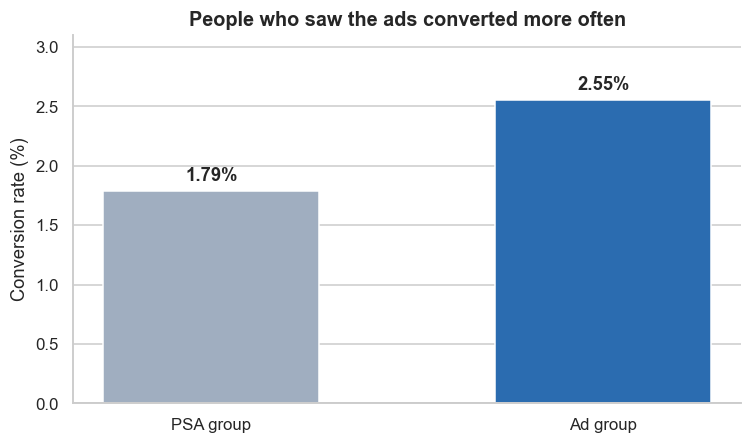

In [4]:
ad_n, ad_c = results.loc['ad', ['users', 'conversions']]
psa_n, psa_c = results.loc['psa', ['users', 'conversions']]
ad_rate, psa_rate = ad_c / ad_n, psa_c / psa_n

difference = ad_rate - psa_rate
margin = 1.96 * math.sqrt(ad_rate * (1 - ad_rate) / ad_n + psa_rate * (1 - psa_rate) / psa_n)

# Could a difference this big happen by chance?
pooled = (ad_c + psa_c) / (ad_n + psa_n)
z = difference / math.sqrt(pooled * (1 - pooled) * (1 / ad_n + 1 / psa_n))
p_value = math.erfc(abs(z) / math.sqrt(2))

print(f'Ad group: {ad_rate:.2%} | PSA group: {psa_rate:.2%}')
print(f'Difference: {difference * 100:.2f} percentage points')
print(f'Likely range: {(difference - margin) * 100:.2f} to {(difference + margin) * 100:.2f} percentage points')
print(f'Relative increase: {ad_rate / psa_rate - 1:.0%}')
print(f'Chance of this result if ads did nothing: {p_value:.1e}')

fig, ax = plt.subplots(figsize=(7, 4.2))
bars = ax.bar(['PSA group', 'Ad group'], [psa_rate * 100, ad_rate * 100], color=[PSA_COLOR, AD_COLOR], width=0.55)
ax.bar_label(bars, labels=[f'{psa_rate:.2%}', f'{ad_rate:.2%}'], padding=4, fontweight='bold')
ax.set_ylabel('Conversion rate (%)'); ax.set_ylim(0, 3.1); ax.grid(axis='x', visible=False)
ax.set_title('People who saw the ads converted more often')
plt.tight_layout(); plt.savefig('figures/01_conversion_rate.png', bbox_inches='tight'); plt.show()

**Insight:** yes. Conversion was 0.77 percentage points higher with ads, a 43% relative increase. The likely range is 0.60 to 0.94 points. A gap this big is very unlikely to be chance, so the company can treat the lift as real.

## 4. Q2: How many conversions did the ads really create?

If the ad group had converted at the PSA group's rate, how many conversions would it have had anyway?

Total conversions in the ad group: 14,423
Would likely have happened anyway: 10,080 (70%)
Extra conversions from ads: 4,343 (30%)
Likely range: 3,360 to 5,326


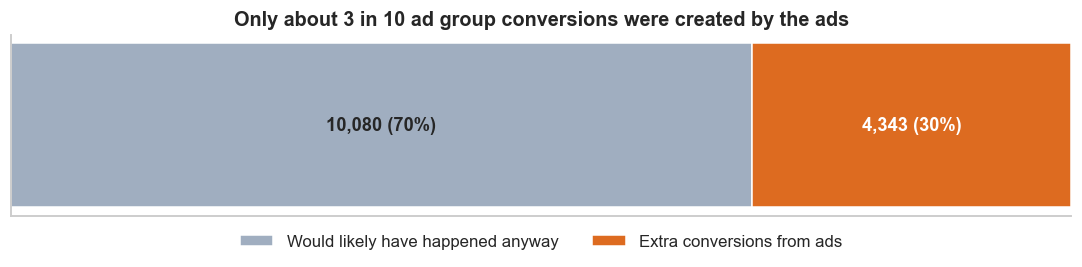

In [5]:
anyway = psa_rate * ad_n
extra = ad_c - anyway
extra_low, extra_high = (difference - margin) * ad_n, (difference + margin) * ad_n

print(f'Total conversions in the ad group: {ad_c:,.0f}')
print(f'Would likely have happened anyway: {anyway:,.0f} ({anyway / ad_c:.0%})')
print(f'Extra conversions from ads: {extra:,.0f} ({extra / ad_c:.0%})')
print(f'Likely range: {extra_low:,.0f} to {extra_high:,.0f}')

fig, ax = plt.subplots(figsize=(10, 2.6))
ax.barh([''], [anyway], color=PSA_COLOR, label='Would likely have happened anyway')
ax.barh([''], [extra], left=[anyway], color=HIGHLIGHT, label='Extra conversions from ads')
ax.text(anyway / 2, 0, f'{anyway:,.0f} ({anyway / ad_c:.0%})', ha='center', va='center', fontweight='bold')
ax.text(anyway + extra / 2, 0, f'{extra:,.0f} ({extra / ad_c:.0%})', ha='center', va='center', fontweight='bold', color='white')
ax.set_xlim(0, ad_c); ax.grid(False); ax.xaxis.set_visible(False)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.02), ncol=2, frameon=False)
ax.set_title('Only about 3 in 10 ad group conversions were created by the ads')
plt.tight_layout(); plt.savefig('figures/02_extra_conversions.png', bbox_inches='tight'); plt.show()

**Insight:** counting all 14,423 conversions would overstate the campaign. About 10,080 would likely have happened anyway and the ads created about 4,343 (likely range 3,360 to 5,326). This extra number is what the company should judge the campaign on.

## 5. Q3: How much advertising does each extra conversion take?

The data has no ad costs or revenue, so I can't say whether the campaign made money. I can show how many ads each extra conversion took, then show the cost at example prices. **These prices are examples, not real figures.**

In [6]:
ads_shown = df.loc[df['group'] == 'ad', 'total_ads'].sum()
ads_per_extra = ads_shown / extra
print(f'Ads shown to the ad group: {ads_shown:,.0f}')
print(f'Ads per extra conversion: {ads_per_extra:,.0f}')

pd.DataFrame({
    'Example cost per 1,000 ads': ['$1', '$5', '$10'],
    'Cost per extra conversion': [f'${ads_per_extra / 1000 * cpm:,.2f}' for cpm in (1, 5, 10)]
})

Ads shown to the ad group: 14,014,701
Ads per extra conversion: 3,227


,"Example cost per 1,000 ads",Cost per extra conversion
0,$1,$3.23
1,$5,$16.13
2,$10,$32.27



**The decision rule is simple:** the campaign pays off if an extra conversion is worth more than this cost. The company can use its real numbers here.

## 6. Q4: Where did the ads make the biggest difference?

I compare the ad and PSA groups among people who saw a similar number of ads or PSAs.

In [7]:
df['exposure'] = pd.cut(df['total_ads'], [0, 9, 24, 49, 99, 199, float('inf')],
                        labels=['1-9', '10-24', '25-49', '50-99', '100-199', '200+'])
df[['user_id', 'exposure']].astype({'exposure': str}).to_sql('exposure_groups', conn, index=False)

by_exposure = pd.read_sql_query('''
SELECT  e.exposure,
        SUM(CASE WHEN u."group" = 'ad'  THEN 1 ELSE 0 END)           AS ad_users,
        SUM(CASE WHEN u."group" = 'psa' THEN 1 ELSE 0 END)           AS psa_users,
        SUM(CASE WHEN u."group" = 'ad'  THEN u.converted ELSE 0 END) AS ad_conversions,
        SUM(CASE WHEN u."group" = 'psa' THEN u.converted ELSE 0 END) AS psa_conversions,
        SUM(CASE WHEN u."group" = 'ad'  THEN u.total_ads ELSE 0 END) AS ads_shown
FROM    users u
JOIN    exposure_groups e ON u.user_id = e.user_id
GROUP BY e.exposure
''', conn).set_index('exposure').loc[['1-9', '10-24', '25-49', '50-99', '100-199', '200+']]

t = by_exposure
t['ad_rate'] = t['ad_conversions'] / t['ad_users'] * 100
t['psa_rate'] = t['psa_conversions'] / t['psa_users'] * 100
t['lift_points'] = t['ad_rate'] - t['psa_rate']
t['margin'] = 196 * ((t['ad_rate'] / 100 * (1 - t['ad_rate'] / 100) / t['ad_users']
                      + t['psa_rate'] / 100 * (1 - t['psa_rate'] / 100) / t['psa_users']) ** 0.5)
t['extra_conversions'] = t['lift_points'] / 100 * t['ad_users']
t['share_of_ads_pct'] = t['ads_shown'] / t['ads_shown'].sum() * 100
t[['ad_users', 'psa_users', 'ad_rate', 'psa_rate', 'lift_points', 'margin', 'extra_conversions', 'share_of_ads_pct']]

,ad_users,psa_users,ad_rate,psa_rate,lift_points,margin,extra_conversions,share_of_ads_pct
exposure,,,,,,,,
1-9,238066,10844,0.31,0.38,-0.07,0.12,-161.10,6.68
10-24,167070,6153,0.95,0.99,-0.05,0.25,-76.31,19.47
25-49,91293,3581,3.35,2.51,0.84,0.53,763.57,22.35
50-99,45709,1916,11.35,5.53,5.82,1.06,"2,660.21",22.27
100-199,16699,769,17.74,10.53,7.21,2.25,"1,204.07",15.98
200+,5740,261,15.57,15.71,-0.13,4.51,-7.69,13.25


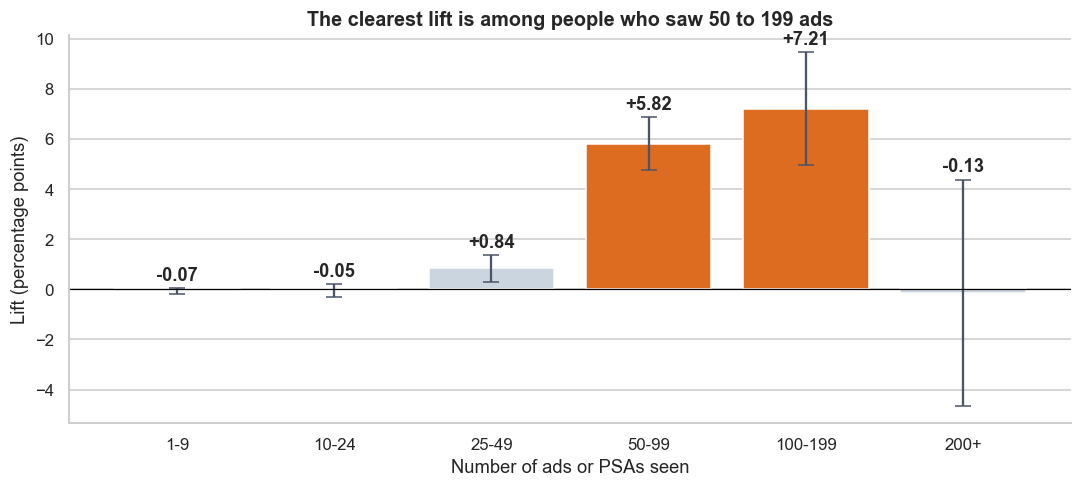

50 to 199 ads: 3,864 of 4,383 estimated extra conversions (88%), from 38% of ads
Under 25 ads: 72% of ad group users, 26% of ads
200+ ads: 1.0% of ad group users, 13% of ads


In [8]:
strong = t['lift_points'] - t['margin'] > 2
fig, ax = plt.subplots(figsize=(10, 4.6))
ax.bar(t.index, t['lift_points'], yerr=t['margin'], capsize=5, ecolor='#4A5568',
       color=[HIGHLIGHT if s else GREY for s in strong])
for i, (v, m) in enumerate(zip(t['lift_points'], t['margin'])):
    ax.text(i, v + m + 0.3, f'{v:+.2f}', ha='center', fontweight='bold')
ax.axhline(0, color='black', lw=0.8)
ax.set_xlabel('Number of ads or PSAs seen'); ax.set_ylabel('Lift (percentage points)')
ax.grid(axis='x', visible=False)
ax.set_title('The clearest lift is among people who saw 50 to 199 ads')
plt.tight_layout(); plt.savefig('figures/03_lift_by_exposure.png', bbox_inches='tight'); plt.show()

top = t.loc[['50-99', '100-199']]
print(f"50 to 199 ads: {top['extra_conversions'].sum():,.0f} of {t['extra_conversions'].sum():,.0f} estimated extra conversions "
      f"({top['extra_conversions'].sum() / t['extra_conversions'].sum():.0%}), from {top['share_of_ads_pct'].sum():.0f}% of ads")
print(f"Under 25 ads: {t.loc[['1-9', '10-24'], 'ad_users'].sum() / t['ad_users'].sum():.0%} of ad group users, "
      f"{t.loc[['1-9', '10-24'], 'share_of_ads_pct'].sum():.0f}% of ads")
print(f"200+ ads: {t.loc['200+', 'ad_users'] / t['ad_users'].sum():.1%} of ad group users, {t.loc['200+', 'share_of_ads_pct']:.0f}% of ads")

**Insight:**
- **Under 25 ads:** no clear lift. This is about 72% of the ad group and 26% of the ads.
- **50 to 199 ads:** the clearest lift, about 88% of the estimated extra conversions from 38% of the ads.
- **200 or more ads:** no clear lift, but with a wide range because only 261 PSA users are in this group. These 1% of users received 13% of the ads.

This doesn't prove more ads cause more conversions. People who see 100 ads are often more active anyway and people may stop seeing ads after they buy. It shows where to test next, not what to change yet.

### A quick check: does the lift depend on the day?

`most_ads_day` is the day each person saw the most ads. It wasn't randomly assigned and the groups aren't split evenly across days, so I check that this doesn't change the main result.

In [9]:
days = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
by_day = df.pivot_table(index='most_ads_day', columns='group', values='converted', aggfunc=['mean', 'size']).loc[days]
by_day.columns = ['ad_rate', 'psa_rate', 'ad_users', 'psa_users']
by_day[['ad_rate', 'psa_rate']] *= 100
by_day['lift_points'] = by_day['ad_rate'] - by_day['psa_rate']
weights = (by_day['ad_users'] + by_day['psa_users']) / len(df)
print(f"Lift after allowing for the day mix: {(weights * by_day['lift_points']).sum():.2f} points (main result {difference * 100:.2f})")
by_day

Lift after allowing for the day mix: 0.78 points (main result 0.77)


,ad_rate,psa_rate,ad_users,psa_users,lift_points
most_ads_day,,,,,
Monday,3.32,2.26,83571,3502,1.07
Tuesday,3.04,1.44,74572,2907,1.60
Wednesday,2.54,1.58,77418,3490,0.96
Thursday,2.16,2.02,79077,3905,0.14
Friday,2.25,1.63,88805,3803,0.62
Saturday,2.13,1.40,78802,2858,0.73
Sunday,2.46,2.06,82332,3059,0.40


**Insight:** the main result holds, at about 0.78 points after allowing for the day mix. Lift ranges from about 0.14 points on Thursday to 1.60 on Tuesday, but seven comparisons can produce some differences by chance, and day wasn't randomly assigned. I wouldn't move ad budget based on this alone.

## 7. Save the results

In [10]:
results.reset_index().to_csv('outputs/ab_test_results.csv', index=False)
t.reset_index().round(3).to_csv('outputs/lift_by_exposure.csv', index=False)
by_day.reset_index().round(3).to_csv('outputs/lift_by_day.csv', index=False)
conn.close()
print('Saved:', sorted(os.listdir('outputs')))

Saved: ['ab_test_results.csv', 'lift_by_day.csv', 'lift_by_exposure.csv']


## 8. Recommendations

| # | Recommendation | Why |
|---|---|---|
| 1 | **Keep the campaign if an extra conversion is worth more than it costs** | The lift is real and each extra conversion took about 3,227 ads. Use the company's real costs and conversion value |
| 2 | **Report extra conversions, not total conversions** | About 70% of the ad group's conversions would likely have happened anyway |
| 3 | **Test a limit of 200 ads per person** | 13% of ads went to 1% of users, with no clear lift. Compare a limit with no limit in a new A/B test |
| 4 | **Test whether reaching 50 ads helps lighter viewers** | Lift is clearest at 50 to 199 ads, but this could be because those users are more active |

## 9. Limitations

- **No costs or revenue:** the data can't show profit. The cost figures above are examples.
- **Exposure and day weren't randomly assigned:** only the ad or PSA group was, so sections 3 and 4 are the strongest results. Section 6 suggests what to test next.
- **Unknown details:** the data doesn't say what the product was, what counts as a conversion or when the campaign ran.
- **Data source:** this is a public Kaggle dataset, so I can't independently confirm how the test was run.
- **PSA users saw something too:** the comparison is ads vs PSAs, not ads vs nothing.

